# Frequency analysis

This example computes the natural frequencies and modes of plates, with and without an in-plane pre-stress, and compares them with the literature: an isotropic and a cross-ply plate against the closed-form solution of a simply supported plate with in-plane forces (Leissa, 1969), and an angle-ply plate against the frequencies of Wang (1997). The nine models of `panels` that the example compares are the plate and cylindrical-shell models of the classical (CLPT), first-order (FSDT) and third-order (TSDT) shear deformation theories, with a large radius $r = 10^8$ m for the shells.

The kinetic energy gives the mass matrix $\boldsymbol{M}$, `Shell.calc_kM`. For harmonic motion, $\boldsymbol{c}(t) = \boldsymbol{c}\, e^{i\omega t}$, the equations of motion become the eigenvalue problem

$$
(\boldsymbol{K} + \lambda^2 \boldsymbol{M})\boldsymbol{c} = \boldsymbol{0}, \qquad \lambda^2 = -\omega_n^2,
$$

solved with `structsolve.freq`, which returns the eigenvalues $\lambda^2$ and the modes. $\omega_n$ is the natural frequency in rad/s. A pre-stress is included by adding the geometric stiffness matrix to the constitutive one, $\boldsymbol{K} = \boldsymbol{K}_C + \boldsymbol{K}_G$: compressive stress resultants lower the frequencies, and tensile ones raise them.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import freq
from panels.shell import Shell

MODELS = ['plate_clpt_donnell', 'cylshell_clpt_donnell',
          'cylshell_clpt_sanders', 'plate_fsdt_donnell', 'plate_tsdt_donnell',
          'cylshell_fsdt_donnell', 'cylshell_fsdt_sanders',
          'cylshell_tsdt_donnell', 'cylshell_tsdt_sanders']


def results_table(rows):
    # Markdown table of (quantity, panels, reference, source) rows
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def natural_frequencies(shell, prestress):
    # natural frequencies (rad/s) and modes, with or without K_G
    K = shell.calc_kC()
    if prestress:
        K = K + shell.calc_kG()
    eigvals, eigvecs = freq(K, shell.calc_kM(), sparse_solver=True,
                            silent=True)
    return np.sqrt(-eigvals).real, eigvecs

## Isotropic plate: closed form with in-plane forces

For a simply supported isotropic plate with the constant membrane resultants $N_{xx}$ and $N_{yy}$, positive in tension, and $N_{xy} = 0$, the modes $w = \sin(m\pi x/a)\sin(n\pi y/b)$ satisfy the plate equation exactly, and the frequencies are given by Eq. (10.44) of Leissa (1969, p. 277):

$$
\rho h\, \omega_{mn}^2 = D \left[\left(\frac{m\pi}{a}\right)^2 + \left(\frac{n\pi}{b}\right)^2\right]^2 + N_{xx}\left(\frac{m\pi}{a}\right)^2 + N_{yy}\left(\frac{n\pi}{b}\right)^2,
$$

with $\rho h$ the mass per unit area (Leissa's $\rho$). The lowest value is the first natural frequency; with compressive resultants it is not necessarily the mode $m = n = 1$ (Leissa, 1969, p. 277). The in-plane inertia does not enter, since the membrane and bending problems of a flat isotropic plate are uncoupled. The plate is the aluminium plate of $1 \times 0.5$ m and 2 mm used throughout this example.

In [2]:
E, nu, h, rho = 70e9, 0.33, 2e-3, 2700.
a, b = 1., 0.5
D = E*h**3/(12*(1 - nu**2))


def omega_closed_form(Nxx, Nyy, nmax=6):
    # Leissa (1969), Eq. (10.44), lowest of the modes m, n <= nmax
    m, n = np.meshgrid(np.arange(1, nmax + 1), np.arange(1, nmax + 1))
    w2 = (D*((m*np.pi/a)**2 + (n*np.pi/b)**2)**2
          + Nxx*(m*np.pi/a)**2 + Nyy*(n*np.pi/b)**2)/(rho*h)
    return np.sqrt(w2.min())


rows = []
for Nxx, Nyy in ((0., 0.), (-200., -50.)):
    s = Shell(model='plate_clpt_donnell', a=a, b=b, stack=[0.], plyt=h,
              laminaprop=(E, nu), rho=rho, m=10, n=10)
    s.Nxx, s.Nyy = Nxx, Nyy
    omegan, _ = natural_frequencies(s, Nxx != 0 or Nyy != 0)
    ref = omega_closed_form(Nxx, Nyy)
    print('Nxx = %g, Nyy = %g N/m: panels %.4f rad/s, closed form %.4f rad/s'
          % (Nxx, Nyy, omegan[0], ref))
    rows.append(('isotropic plate, $N_{xx} = %g$, $N_{yy} = %g$ N/m, $\\omega_1$ (rad/s)'
                 % (Nxx, Nyy), omegan[0], ref,
                 'Leissa (1969), Eq. (10.44), p. 277'))
results_table(rows)

Nxx = 0, Nyy = 0 N/m: panels 153.6772 rad/s, closed form 153.6785 rad/s
Nxx = -200, Nyy = -50 N/m: panels 151.2799 rad/s, closed form 151.2812 rad/s


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| isotropic plate, $N_{xx} = 0$, $N_{yy} = 0$ N/m, $\omega_1$ (rad/s) | 153.677 | 153.678 | -8.22e-06 | Leissa (1969), Eq. (10.44), p. 277 |
| isotropic plate, $N_{xx} = -200$, $N_{yy} = -50$ N/m, $\omega_1$ (rad/s) | 151.28 | 151.281 | -8.22e-06 | Leissa (1969), Eq. (10.44), p. 277 |

## Angle-ply plate: comparison with Wang (1997)

Singha and Ganapathi (2005, Table 1, p. 58) list the first six non-dimensional natural frequencies

$$
\bar{\omega} = \frac{\omega a^2}{\pi^2 h}\sqrt{\frac{\rho}{E_T}}
$$

of a simply supported square plate with the symmetric angle-ply laminate $[45/-45/45/-45/45]$ of plies of equal thickness, $a/b = 1$ and $a/h = 100$, computed with their finite element and with the thin-plate solution of Wang (1997). The ply properties are $E_L/E_T = 40$, $G_{LT}/E_T = 0.6$, $G_{TT}/E_T = 0.5$, $\nu_{LT} = 0.25$ (Singha and Ganapathi, 2005, p. 58), so $G_{12} = G_{13} = G_{LT}$ and $G_{23} = G_{TT}$ in `laminaprop`. Since $\bar{\omega}$ is non-dimensional, $E_T = 1$ and $\rho = 1$ are used. Their simply supported edges have $u = v = w = 0$, as the default boundary conditions of `panels`.

The bending-twisting coupling terms $D_{16}$ and $D_{26}$ of the angle-ply laminate are not zero, so there is no closed-form solution and the convergence in the number of terms is slower than for an orthotropic plate; $m = n = 15$ terms are used.

In [3]:
ET = 1.
lam_singha = (40*ET, ET, 0.25, 0.6*ET, 0.6*ET, 0.5*ET)
a_s = 1.
h_s = a_s/100
# Singha and Ganapathi (2005), Table 1, skew angle 0, SS
WANG = [2.4339, 4.9865, 6.1818, 8.4870, 10.2536, 11.6464]
SINGHA = [2.4343, 4.9854, 6.1823, 8.4827, 10.2464, 11.6432]
omegabar = {}
for model in MODELS:
    s = Shell(model=model, a=a_s, b=a_s, r=1.e8, stack=[45, -45, 45, -45, 45],
              plyt=h_s/5, laminaprop=lam_singha, rho=1., m=15, n=15)
    omegan, _ = natural_frequencies(s, False)
    omegabar[model] = omegan[:6]*a_s**2/(np.pi**2*h_s)*np.sqrt(s.rho/ET)
    print('%-22s %s' % (model, np.round(omegabar[model], 4)))
print('%-22s %s' % ('Wang (1997)', np.array(WANG)))
print('%-22s %s' % ('Singha and Ganapathi', np.array(SINGHA)))

plate_clpt_donnell     [ 2.433   4.9854  6.1786  8.4838 10.2492 11.638 ]


cylshell_clpt_donnell  [ 2.433   4.9854  6.1786  8.4838 10.2492 11.638 ]


cylshell_clpt_sanders  [ 2.433   4.9854  6.1786  8.4838 10.2492 11.638 ]


plate_fsdt_donnell     [ 2.4231  4.9497  6.1191  8.3851 10.1053 11.4336]


plate_tsdt_donnell     [ 2.4227  4.9513  6.1191  8.391  10.111  11.4359]


cylshell_fsdt_donnell  [ 2.4231  4.9497  6.1191  8.3851 10.1053 11.4336]


cylshell_fsdt_sanders  [ 2.4231  4.9497  6.1191  8.3851 10.1053 11.4336]


cylshell_tsdt_donnell  [ 2.4227  4.9513  6.1191  8.391  10.111  11.4359]


cylshell_tsdt_sanders  [ 2.4227  4.9513  6.1191  8.391  10.111  11.4359]
Wang (1997)            [ 2.4339  4.9865  6.1818  8.487  10.2536 11.6464]
Singha and Ganapathi   [ 2.4343  4.9854  6.1823  8.4827 10.2464 11.6432]


The first frequency of every model, and the first six of a CLPT and an FSDT model, against the values of Wang (1997):

In [4]:
src = 'Wang (1997), in Singha and Ganapathi (2005), Table 1'
rows = []
for model in MODELS:
    rows.append(('`%s`, $\\bar{\\omega}_1$' % model, omegabar[model][0],
                 WANG[0], src))
for model in ['plate_clpt_donnell', 'plate_fsdt_donnell']:
    for i in range(1, 6):
        rows.append(('`%s`, $\\bar{\\omega}_%d$' % (model, i + 1),
                     omegabar[model][i], WANG[i], src))
results_table(rows)

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, $\bar{\omega}_1$ | 2.43298 | 2.4339 | -3.77e-04 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `cylshell_clpt_donnell`, $\bar{\omega}_1$ | 2.43298 | 2.4339 | -3.77e-04 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `cylshell_clpt_sanders`, $\bar{\omega}_1$ | 2.43298 | 2.4339 | -3.77e-04 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_fsdt_donnell`, $\bar{\omega}_1$ | 2.42311 | 2.4339 | -4.43e-03 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_tsdt_donnell`, $\bar{\omega}_1$ | 2.4227 | 2.4339 | -4.60e-03 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `cylshell_fsdt_donnell`, $\bar{\omega}_1$ | 2.42311 | 2.4339 | -4.43e-03 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `cylshell_fsdt_sanders`, $\bar{\omega}_1$ | 2.42311 | 2.4339 | -4.43e-03 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `cylshell_tsdt_donnell`, $\bar{\omega}_1$ | 2.4227 | 2.4339 | -4.60e-03 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `cylshell_tsdt_sanders`, $\bar{\omega}_1$ | 2.4227 | 2.4339 | -4.60e-03 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_clpt_donnell`, $\bar{\omega}_2$ | 4.98542 | 4.9865 | -2.17e-04 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_clpt_donnell`, $\bar{\omega}_3$ | 6.1786 | 6.1818 | -5.18e-04 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_clpt_donnell`, $\bar{\omega}_4$ | 8.48381 | 8.487 | -3.76e-04 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_clpt_donnell`, $\bar{\omega}_5$ | 10.2492 | 10.2536 | -4.34e-04 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_clpt_donnell`, $\bar{\omega}_6$ | 11.638 | 11.6464 | -7.21e-04 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_fsdt_donnell`, $\bar{\omega}_2$ | 4.94965 | 4.9865 | -7.39e-03 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_fsdt_donnell`, $\bar{\omega}_3$ | 6.11906 | 6.1818 | -1.01e-02 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_fsdt_donnell`, $\bar{\omega}_4$ | 8.38508 | 8.487 | -1.20e-02 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_fsdt_donnell`, $\bar{\omega}_5$ | 10.1053 | 10.2536 | -1.45e-02 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |
| `plate_fsdt_donnell`, $\bar{\omega}_6$ | 11.4336 | 11.6464 | -1.83e-02 | Wang (1997), in Singha and Ganapathi (2005), Table 1 |

The CLPT models agree with the thin-plate solution of Wang (1997) within about 0.1% for the six modes. The FSDT and TSDT models give frequencies 0.4% (first mode) to 1.8% (sixth mode) lower: the transverse shear flexibility is not negligible at $a/h = 100$ for this material, with $E_L/G_{LT} = 67$, and its effect grows with the number of half-waves. Wang's solution is based on the thin-plate theory and does not include it; the finite element of Singha and Ganapathi (2005), with transverse shear, gives values close to Wang's.

## Cross-ply plate with and without pre-stress

Leissa (1969, p. 267) states that no results were published for plates with both in-plane forces and orthotropy. The plate equation with in-plane forces, Eq. (10.1) of Leissa (1969, p. 267), is however written for rectangular orthotropy, and for a symmetric cross-ply laminate, with $\boldsymbol{B} = \boldsymbol{0}$ and $D_{16} = D_{26} = 0$, the constants of Eq. (9.24) of Leissa (1969, p. 250) are $D_x = D_{11}$, $D_y = D_{22}$ and $D_{xy} = D_{12} + 2D_{66}$. The simply supported modes $w = \sin(m\pi x/a)\sin(n\pi y/b)$ satisfy Eq. (10.1) exactly, which gives, as Eq. (10.44) for the isotropic plate,

$$
\rho h\, \omega_{mn}^2 = D_{11}\left(\frac{m\pi}{a}\right)^4 + 2(D_{12} + 2D_{66})\left(\frac{m\pi}{a}\right)^2\left(\frac{n\pi}{b}\right)^2 + D_{22}\left(\frac{n\pi}{b}\right)^4 + N_{xx}\left(\frac{m\pi}{a}\right)^2 + N_{yy}\left(\frac{n\pi}{b}\right)^2.
$$

The plate of $1 \times 0.5$ m has the laminate $[0/90/90/0]$ of carbon/epoxy plies of 0.125 mm, $E_{11} = 142.5$ GPa, $E_{22} = 8.7$ GPa, $\nu_{12} = 0.28$, $G_{12} = G_{13} = G_{23} = 5.1$ GPa, and density 1300 kg/m³; the pre-stress is $N_{xx} = -30$ N/m and $N_{yy} = -5$ N/m, below the buckling load. The plate is thin, $a/h = 2000$, so the nine models agree. The bending stiffness matrix $\boldsymbol{D}$ is taken from the laminate of the `Shell` object, `Shell.lam`.

In [5]:
lam_cfrp = (142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9)
Nxx, Nyy = -30., -5.


def omega_orthotropic(p, Nxx, Nyy, nmodes=3, nmax=12):
    # Leissa (1969), Eq. (10.1) with the modes sin(m pi x/a) sin(n pi y/b)
    Dm = p.lam.D
    h = sum(p.plyts)
    m, n = np.meshgrid(np.arange(1, nmax + 1), np.arange(1, nmax + 1))
    km, kn = m*np.pi/p.a, n*np.pi/p.b
    w2 = (Dm[0, 0]*km**4 + 2*(Dm[0, 1] + 2*Dm[2, 2])*km**2*kn**2
          + Dm[1, 1]*kn**4 + Nxx*km**2 + Nyy*kn**2)/(p.rho*h)
    return np.sort(np.sqrt(w2.ravel()))[:nmodes]


rows = []
first_modes = {}
for model in MODELS:
    for prestress in (False, True):
        p = Shell(model=model, a=1., b=0.5, r=1.e8, stack=[0, 90, 90, 0],
                  plyt=0.125e-3, rho=1.3e3, m=12, n=12, laminaprop=lam_cfrp)
        p.Nxx, p.Nyy = Nxx, Nyy
        omegan, eigvecs = natural_frequencies(p, prestress)
        ref = omega_orthotropic(p, Nxx if prestress else 0.,
                                Nyy if prestress else 0.)
        print('%-22s pre-stress %-5s: panels %s, closed form %s rad/s'
              % (model, prestress, np.round(omegan[:3], 4), np.round(ref, 4)))
        rows.append(('`%s`, pre-stress %s, $\\omega_1$ (rad/s)'
                     % (model, prestress), omegan[0], ref[0],
                     'Leissa (1969), Eq. (10.1), p. 267'))
        if model == 'plate_clpt_donnell':
            first_modes[prestress] = (p, eigvecs[:, 0])
print('D16 = %.2e, D26 = %.2e N m, max |B| = %.2e N'
      % (p.lam.D[0, 2], p.lam.D[1, 2], np.abs(p.lam.B).max()))
results_table(rows)

plate_clpt_donnell     pre-stress False: panels [ 31.517   66.5314 105.0639], closed form [ 31.517   66.5315 105.0641] rad/s


plate_clpt_donnell     pre-stress True : panels [15.301  47.9653 96.7894], closed form [15.301  47.9653 96.7896] rad/s


cylshell_clpt_donnell  pre-stress False: panels [ 31.517   66.5314 105.0639], closed form [ 31.517   66.5315 105.0641] rad/s


cylshell_clpt_donnell  pre-stress True : panels [15.301  47.9653 96.7894], closed form [15.301  47.9653 96.7896] rad/s


cylshell_clpt_sanders  pre-stress False: panels [ 31.517   66.5314 105.0639], closed form [ 31.517   66.5315 105.0641] rad/s


cylshell_clpt_sanders  pre-stress True : panels [15.301  47.9653 96.7894], closed form [15.301  47.9653 96.7896] rad/s


... (9 outputs left out)

cylshell_tsdt_donnell  pre-stress True : panels [15.3007 47.9643 96.788 ], closed form [15.301  47.9653 96.7896] rad/s


cylshell_tsdt_sanders  pre-stress False: panels [ 31.5169  66.5307 105.0626], closed form [ 31.517   66.5315 105.0641] rad/s


cylshell_tsdt_sanders  pre-stress True : panels [15.3007 47.9643 96.788 ], closed form [15.301  47.9653 96.7896] rad/s
D16 = 3.11e-19, D26 = 1.04e-17 N m, max |B| = 2.84e-14 N


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, pre-stress False, $\omega_1$ (rad/s) | 31.517 | 31.517 | -5.14e-07 | Leissa (1969), Eq. (10.1), p. 267 |
| `plate_clpt_donnell`, pre-stress True, $\omega_1$ (rad/s) | 15.301 | 15.301 | -5.14e-07 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_clpt_donnell`, pre-stress False, $\omega_1$ (rad/s) | 31.517 | 31.517 | -5.14e-07 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_clpt_donnell`, pre-stress True, $\omega_1$ (rad/s) | 15.301 | 15.301 | -5.14e-07 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_clpt_sanders`, pre-stress False, $\omega_1$ (rad/s) | 31.517 | 31.517 | -5.14e-07 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_clpt_sanders`, pre-stress True, $\omega_1$ (rad/s) | 15.301 | 15.301 | -5.14e-07 | Leissa (1969), Eq. (10.1), p. 267 |
| `plate_fsdt_donnell`, pre-stress False, $\omega_1$ (rad/s) | 31.5168 | 31.517 | -4.70e-06 | Leissa (1969), Eq. (10.1), p. 267 |
| `plate_fsdt_donnell`, pre-stress True, $\omega_1$ (rad/s) | 15.3007 | 15.301 | -1.83e-05 | Leissa (1969), Eq. (10.1), p. 267 |
| `plate_tsdt_donnell`, pre-stress False, $\omega_1$ (rad/s) | 31.5169 | 31.517 | -4.13e-06 | Leissa (1969), Eq. (10.1), p. 267 |
| `plate_tsdt_donnell`, pre-stress True, $\omega_1$ (rad/s) | 15.3007 | 15.301 | -1.59e-05 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_fsdt_donnell`, pre-stress False, $\omega_1$ (rad/s) | 31.5168 | 31.517 | -4.70e-06 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_fsdt_donnell`, pre-stress True, $\omega_1$ (rad/s) | 15.3007 | 15.301 | -1.83e-05 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_fsdt_sanders`, pre-stress False, $\omega_1$ (rad/s) | 31.5168 | 31.517 | -4.70e-06 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_fsdt_sanders`, pre-stress True, $\omega_1$ (rad/s) | 15.3007 | 15.301 | -1.83e-05 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_tsdt_donnell`, pre-stress False, $\omega_1$ (rad/s) | 31.5169 | 31.517 | -4.13e-06 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_tsdt_donnell`, pre-stress True, $\omega_1$ (rad/s) | 15.3007 | 15.301 | -1.59e-05 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_tsdt_sanders`, pre-stress False, $\omega_1$ (rad/s) | 31.5169 | 31.517 | -4.13e-06 | Leissa (1969), Eq. (10.1), p. 267 |
| `cylshell_tsdt_sanders`, pre-stress True, $\omega_1$ (rad/s) | 15.3007 | 15.301 | -1.59e-05 | Leissa (1969), Eq. (10.1), p. 267 |

The pre-stress lowers the first frequency by about half, and the nine models agree with the closed form within $10^{-4}$: the CLPT models within $10^{-6}$, the precision of the Ritz approximation, and the shear deformation theories within $2 \times 10^{-5}$, since at $a/h = 2000$ the transverse shear hardly matters.

The first mode of the plate model, without and with the pre-stress:

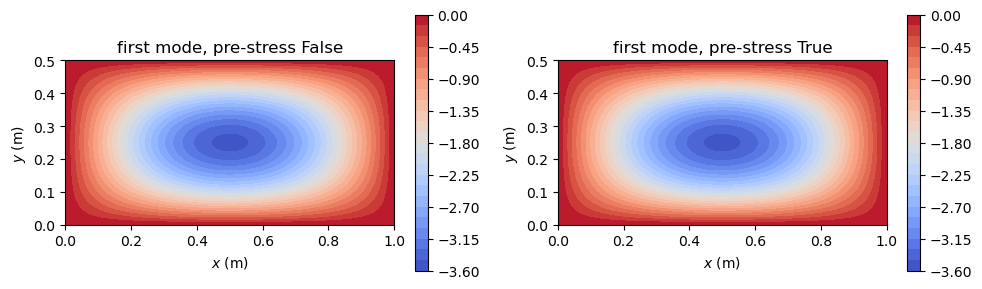

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (prestress, (p, c)) in zip(axes, first_modes.items()):
    mesh, fields = p.uvw(np.real(c), gridx=101, gridy=61)
    cf = ax.contourf(mesh['Xs'], mesh['Ys'], fields['w'], levels=30,
                     cmap='coolwarm')
    fig.colorbar(cf, ax=ax)
    ax.set_title('first mode, pre-stress %s' % prestress)
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
    ax.set_aspect('equal')
fig.tight_layout()
plt.show()

## References

1. A. W. Leissa, "Vibration of plates". NASA SP-160, National Aeronautics and Space Administration, Washington, D.C., 1969. https://ntrs.nasa.gov/citations/19700009156.
2. M. K. Singha and M. Ganapathi, "A parametric study on supersonic flutter behavior of laminated composite skew flat panels". Composite Structures, 69(1):55-63, 2005. https://doi.org/10.1016/j.compstruct.2004.04.018.
3. S. Wang, "Vibration of thin skew fibre reinforced composite laminates". Journal of Sound and Vibration, 201(3):335-352, 1997. https://doi.org/10.1006/jsvi.1996.0745.